In [24]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import geopandas as gpd

#Calgarys internal coordinate uses epsg 3776
EPSG = 3776

STOPS_GJSON = './data/Calgary_Transit_Stops_20261123.geojson'


In [14]:
#local functions

def get_grouped_dtypes(gdf):
    """
    Returns a dictionary of grouped data types for a GeoDataFrame (or DataFrame).
    
    Parameters:
    gdf (GeoDataFrame): The input GeoDataFrame.
    
    Returns:
    dict: A dictionary where keys are data types and values are lists of column names with that data type.
    """
    grouped_dtypes = gdf.columns.to_series().groupby(gdf.dtypes, sort=False).groups

    for dtype, cols in grouped_dtypes.items():
        print(f"\n--- {dtype} ({len(cols)}) ---")
        print(list(cols))
    return




In [15]:
stops_gdf = gpd.read_file(STOPS_GJSON)

#check data types
get_grouped_dtypes(stops_gdf)



--- str (10) ---
[':id', ':version', 'teleride_number', 'stop_name', 'status', 'globalid', ':@computed_region_4b54_tmc4', ':@computed_region_kxmf_bzkv', ':@computed_region_4a3i_ccfj', ':@computed_region_p8tp_5dkv']

--- datetime64[ms, UTC] (4) ---
[':created_at', ':updated_at', 'create_dt_utc', 'mod_dt_utc']

--- geometry (1) ---
['geometry']


In [16]:
#convert teleride_number to number
stops_gdf['teleride_number'] =  stops_gdf['teleride_number'].astype(int)

#filter out inactive stopsscree
stops_gdf = stops_gdf[stops_gdf['status'] == 'ACTIVE']

#check the data types and null values again after filtering
if stops_gdf.isnull().any().any():
    print("There are null values in the GeoDataFrame.")
    print(stops_gdf.isnull().sum())


stops_proj = stops_gdf[['teleride_number', 'geometry', 'stop_name']].to_crs(epsg=EPSG)  # Web Mercator projection


There are null values in the GeoDataFrame.
:id                             0
:version                        0
:created_at                     0
:updated_at                     0
teleride_number                 0
stop_name                       0
status                          0
create_dt_utc                   0
mod_dt_utc                      0
globalid                        0
:@computed_region_4b54_tmc4    14
:@computed_region_kxmf_bzkv    14
:@computed_region_4a3i_ccfj    14
:@computed_region_p8tp_5dkv    14
geometry                        0
dtype: int64


In [17]:
#load census data
census_gdf = gpd.read_file('./data/Census_by_Community_2019_20261123.geojson')

get_grouped_dtypes(census_gdf)

#counts appear to be stored as strings, we should convert any column with '_cnt' to numeric
for col in census_gdf.columns:
    if col.endswith('_cnt'):
        census_gdf[col] = pd.to_numeric(census_gdf[col], errors='coerce')


#local projection, only for the columns we need for analysis
cols_to_keep = ['res_cnt', 'cat_cnt', 'dog_cnt', 'geometry', 'name']
census_proj = census_gdf[cols_to_keep].to_crs(epsg=EPSG)





--- str (143) ---
[':id', ':version', 'class', 'class_code', 'comm_code', 'name', 'sector', 'srg', 'comm_structure', 'cnss_yr', 'foip_ind', 'res_cnt', 'dwell_cnt', 'prsch_chld', 'elect_cnt', 'emplyd_cnt', 'ownshp_cnt', 'dog_cnt', 'cat_cnt', 'pub_sch', 'sep_sch', 'pubsep_sch', 'other_sch', 'unknwn_sch', 'sing_famly', 'duplex', 'multi_plex', 'apartment', 'town_house', 'manuf_home', 'conv_struc', 'comunl_hse', 'res_comm', 'other_res', 'nursing_hm', 'other_inst', 'hotel_cnt', 'other_misc', 'apt_no_res', 'apt_occpd', 'apt_owned', 'apt_person', 'apt_vacant', 'apt_uc', 'apt_na', 'cnv_no_res', 'cnv_occpd', 'cnv_owned', 'cnv_person', 'cnv_vacant', 'cnv_uc', 'cnv_na', 'dup_no_res', 'dup_occpd', 'dup_owned', 'dup_person', 'dup_vacant', 'dup_uc', 'dup_na', 'mfh_no_res', 'mfh_occpd', 'mfh_owned', 'mfh_person', 'mfh_vacant', 'mfh_uc', 'mfh_na', 'mul_no_res', 'mul_occpd', 'mul_owned', 'mul_person', 'mul_vacant', 'mul_uc', 'mul_na', 'oth_no_res', 'oth_occpd', 'oth_owned', 'oth_person', 'oth_vacant', 

In [18]:
#calculate the area and residence density for each community
census_proj['area'] = census_proj['geometry'].area
census_proj['res_density'] = census_proj['res_cnt'] / census_proj['area']

#get the community name each stop is in with sjoin
stops_proj = gpd.sjoin(stops_proj, census_proj[['name', 'geometry']], how='left', predicate = 'within').drop(columns="index_right")

#get the number of stops within each community from stops_proj and add it as column to census_proj
stop_counts = stops_proj.groupby('name').size().reset_index(name='stop_count')
census_proj = census_proj.merge(stop_counts, on='name', how='left')

#calculate the stop density for each community
census_proj['stop_density'] = census_proj['stop_count'] / census_proj['area']


In [96]:
# for each stop, calculate number of stops within a 100 m distance

# 1. Query the spatial index for all pairs within distance (e.g., 500 meters)
# Returns a 2xM array: [source_indices, neighbor_indices]
src_idx, nbr_idx = stops_proj.sindex.query(
    stops_proj.geometry, 
    predicate="dwithin", 
    distance=500
)

# 2. Exclude self-matches (where a point matches with itself)
mask = src_idx != nbr_idx
src_idx = src_idx[mask]

# 3. Count occurrences per source point
# minlength ensures points with 0 neighbors still get a count of 0
counts = np.bincount(src_idx, minlength=len(stops_proj))

# 4. Assign back to your GeoDataFrame
stops_proj["neighbour_count"] = counts


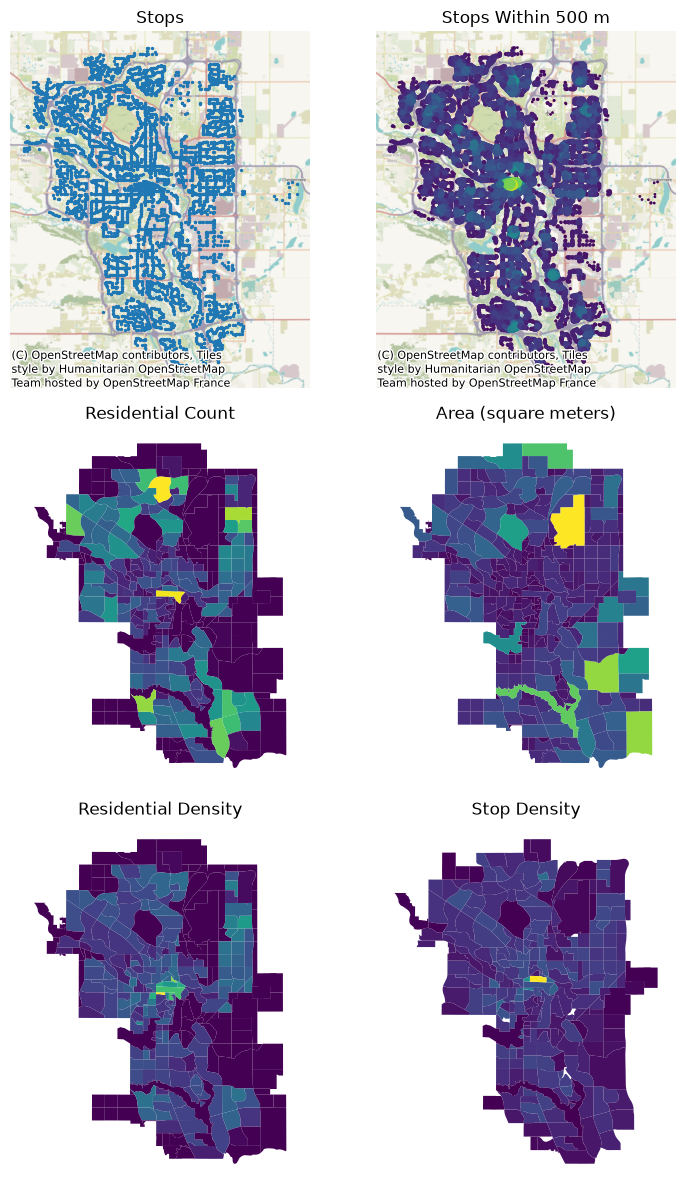

In [118]:

#make subplot figures with 2 rows


n_rows = 3
n_cols = 2
plt_index = 0

plt.figure(figsize=(4*n_cols,4*n_rows))


#plot the stops
plt_index += 1
plt.subplot(n_rows, n_cols, plt_index)
stops_proj.plot(tiles = True, markersize=2, ax=plt.gca())
plt.title('Stops')

#plot the stops within threshold distance
plt_index += 1
plt.subplot(n_rows, n_cols, plt_index)
stops_proj.plot('neighbour_count', tiles = True, markersize=stops_proj['neighbour_count'], ax=plt.gca())
plt.title('Stops Within 500 m')

#plot the res_cnt by community
plt_index += 1
plt.subplot(n_rows, n_cols, plt_index)
census_proj.plot('res_cnt', ax=plt.gca())
plt.title('Residential Count')

#plot the area by community
plt_index += 1
plt.subplot(n_rows, n_cols, plt_index)
census_proj.plot('area', ax=plt.gca())
plt.title('Area (square meters)')

#plot the density
plt_index += 1
plt.subplot(n_rows, n_cols, plt_index)
census_proj.plot('res_density', ax=plt.gca())
plt.title('Residential Density')

#plot the stop density
plt_index += 1
plt.subplot(n_rows, n_cols, plt_index)
census_proj.plot('stop_density', ax = plt.gca())
plt.title('Stop Density')
plt.gca().set_frame_on(False)

for i in range(1, n_rows * n_cols + 1):
    plt.subplot(n_rows, n_cols, i)  
    plt.xticks([])
    plt.yticks([])
    plt.xlabel('')
    plt.ylabel('')
    plt.box(False)

plt.tight_layout()


In [ ]:
#load and clean LRT stations

LRT_FILE = './data/Transit_LRT_Stations_20261124.geojson'

lrt_gpd = gpd.read_file(LRT_FILE)

print(get_grouped_dtypes(lrt_gpd))


--- str (15) ---
[':id', ':version', 'stationnam', 'leg', 'direction', 'dist_nb', 'dist_sb', 'dist_eb', 'dist_wb', 'route', 'status', ':@computed_region_4b54_tmc4', ':@computed_region_4a3i_ccfj', ':@computed_region_kxmf_bzkv', ':@computed_region_p8tp_5dkv']

--- datetime64[ms, UTC] (2) ---
[':created_at', ':updated_at']

--- geometry (1) ---
['geometry']
None


In [127]:
lrt_gpd

,:id,:version,:created_at,:updated_at,stationnam,leg,direction,dist_nb,dist_sb,dist_eb,dist_wb,route,status,:@computed_region_4b54_tmc4,:@computed_region_4a3i_ccfj,:@computed_region_kxmf_bzkv,:@computed_region_p8tp_5dkv,geometry
0,row-nkck-khd9_fip3,rv-8nkq-y8mk-pj5x,2026-11-01 12:07:16.961+00:00,2026-11-01 12:07:22.147+00:00,45 Street SW Station,West,West/East,NaN,NaN,NaN,NaN,202,Current,14,1,234,14,POINT (-114.15421 51.03797)
1,row-wvsq.2h52~n8mb,rv-b6iz_j83v~j4cx,2026-11-01 12:07:16.961+00:00,2026-11-01 12:07:22.147+00:00,Sirocco Station,West,West/East,NaN,NaN,NaN,NaN,202,Current,1,1,68,14,POINT (-114.16906 51.03839)
2,row-h82p_huh2-8ckb,rv-wrbp~97jx-vv6r,2026-11-01 12:07:16.961+00:00,2026-11-01 12:07:22.147+00:00,Rundle Station,NE,North/South,1276.0,1845.0,0.0,0.0,202,Current,9,4,83,3,POINT (-113.98174 51.07587)
3,row-3wta~bgrg-yj4c,rv-ua88.ch7f~22mf,2026-11-01 12:07:16.961+00:00,2026-11-01 12:07:22.147+00:00,Anderson Station,SW,North/South,1064.0,2041.0,0.0,0.0,201,Current,8,1,7,5,POINT (-114.07453 50.95432)
4,row-scih_tt6q_hsvp,rv-8e59-iyyg-4umt,2026-11-01 12:07:16.961+00:00,2026-11-01 12:07:22.147+00:00,Southland Station,SW,North/South,1654.0,1064.0,0.0,0.0,201,Current,8,1,7,5,POINT (-114.07657 50.96358)
5,row-sesk~2pw8_hucf,rv-w752.mm66_2x76,2026-11-01 12:07:16.961+00:00,2026-11-01 12:07:22.147+00:00,Downtown West - Kerby Station,DTWestbnd,West/East,0.0,0.0,NaN,NaN,202,Current,14,1,45,2,POINT (-114.08726 51.04724)
6,row-wm8m-k5sk-acqr,rv-rq27~sfgj.nnfz,2026-11-01 12:07:16.961+00:00,2026-11-01 12:07:22.147+00:00,Brentwood Station,NW,North/South,2372.0,1013.0,0.0,0.0,201,Current,13,2,50,4,POINT (-114.13182 51.08705)
7,row-fzh7-yatp~ztgz,rv-gqjs-xhve~2qak,2026-11-01 12:07:16.961+00:00,2026-11-01 12:07:22.147+00:00,7th Street SW Station,DTWestbnd,West,1376.0,0.0,265.0,334.0,201/202,Current,14,1,262,2,POINT (-114.07744 51.04699)
8,row-d37v_tiir.gzzb,rv-66w5.k3zm-t54i,2026-11-01 12:07:16.961+00:00,2026-11-01 12:07:22.147+00:00,City Hall Station,DTWestbnd,West,NaN,NaN,200.0,NaN,201/202,Current,7,3,262,7,POINT (-114.05702 51.04639)
9,row-m74d_pj7n-jw66,rv-uwsb~aynj~xctv,2026-11-01 12:07:16.961+00:00,2026-11-01 12:07:22.147+00:00,SAIT/ACAD/Jubilee Station,NW,North/South,923.0,1026.0,0.0,0.0,201,Current,7,2,40,7,POINT (-114.09133 51.06314)


([], [])

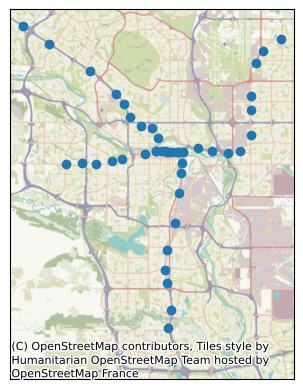

In [126]:
lrt_proj = lrt_gpd.to_crs(epsg = EPSG)

lrt_proj.plot(tiles = True)
plt.xlabel('')
plt.ylabel('')
plt.xticks([])
plt.yticks([])